# Hälsostudie – Dataanalys

## Introduktion

Syftet med denna analys är att undersöka hälsodata från 800 deltagare. Analyserar  ålder, vikt, längd, blodtryck, kolesterol, rökvanor och förekomst av sjukdom.

**Frågor **
- Hur stor andel av deltagarna har sjukdomen, och hur nära kommer en binomial simulering den observerade andelen?
- Vilket 95-procentigt konfidensintervall får vi för medelvärdet av systoliskt blodtryck?
- **Har rökare högre genomsnittligt systoliskt blodtryck än icke-rökare?**
- **Skiljer sig sjukdomsandelen mellan rökare och icke-rökare?** (kompletterande analys)
- Hur förändras statistisk power under olika antagna effekter?

- Kan systoliskt blodtryck förutsägas utifrån ålder, och förbättras prognosen när vikt och kolesterol och rövanor inkluderas i en multipel regressionsmodell?

Målet är att använda beskrivande statistik, visualiseringar, simuleringar, statistiska metoder och linjär regression för att identifiera mönster, undersöka samband mellan variabler och dra slutsatser utifrån datasetet.

## 1. Importera bibliotek och skapa reproducerbarhet



In [1]:
%load_ext autoreload
%autoreload 2

In [ ]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd().resolve()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
if not (ROOT / 'src').exists():
    raise FileNotFoundError('Starta Jupyter i projektroten eller notebooks/.')
sys.path.insert(0, str(ROOT))

from src.health_analyzer import HealthAnalyzer
from src.simulation import ( 
    simulate_disease, simulated_power, analytical_power_proportions, 
    simulated_power_proportions, simulated_power_curve
)
from src.visualization import (
    plot_distribution, plot_group_comparison, plot_smoking_distribution,
    plot_correlation_matrix, plot_relationship, plot_disease_boxplot, 
    plot_smoking_disease, plot_disease_simulation, plot_bootstrap_ci, plot_smoking_bp, 
    plot_power_curve, plot_simple_regression,
    plot_multiple_regression, plot_interactive_simple, plot_interactive_multiple,
    plot_disease_proportion_ci, plot_power_proportions
)
SEED = 42
DATA_PATH = ROOT / 'data' / 'health_study_dataset.csv'


## 2. Läs in data



In [3]:
analyzer = HealthAnalyzer(DATA_PATH)
df = analyzer.df
print('Datasetets form:', df.shape)
display(df.head())
display(df.dtypes.to_frame('Datatyp'))


Datasetets form: (800, 10)


,id,age,sex,height,weight,systolic_bp,cholesterol,smoker,disease,bmi
0,1,57,F,168.9,65.8,141.8,4.58,No,0,23.065698
1,2,47,M,180.4,95.9,144.8,5.18,Yes,0,29.467653
2,3,59,F,169.9,82.2,151.7,6.16,No,0,28.476398
3,4,72,M,157.7,93.1,151.0,6.63,No,0,37.435729
4,5,46,M,192.6,104.1,144.1,5.21,No,0,28.063263


,Datatyp
id,int64
age,int64
sex,str
height,float64
weight,float64
systolic_bp,float64
cholesterol,float64
smoker,str
disease,int64
bmi,float64


### 2.1 Datakvalitet

Kontrollera även kategorier och rimliga värden.

BMI beräknas som vikt i kilogram delat med längd i meter i kvadrat.


In [4]:
# Kontrollera kategorier
quality = analyzer.quality()

print('Antal rader:', quality['antal_rader'])
print('Antal kolumner:', quality['antal_kolumner'])
print('Dubbletter:', quality['dubbletter'])

print("Kön:", sorted(df["sex"].dropna().unique()))
print("Rökare:", sorted(df["smoker"].dropna().unique()))
print("Sjukdom:", sorted(df["disease"].dropna().unique()))


display(quality['saknade'].to_frame('Saknade värden'))
display(quality['ogiltiga'].to_frame('Ogiltiga värden'))
display(df[['height','weight','bmi']].head())

print("""
Tolkning: Datasetet innehåller 800 deltagare och inga duplicerade hela rader enligt kontrollen. 
Kategorierna kodas som F/M, Yes/No och 0/1. BMI är en härledd variabel, inte ett ursprungligt mätvärde. 
""")

Antal rader: 800
Antal kolumner: 10
Dubbletter: 0
Kön: ['F', 'M']
Rökare: ['No', 'Yes']
Sjukdom: [np.int64(0), np.int64(1)]


,Saknade värden
id,0
age,0
sex,0
height,0
weight,0
systolic_bp,0
cholesterol,0
smoker,0
disease,0
bmi,0


,Ogiltiga värden
age,0
weight,0
height,0
systolic_bp,0
cholesterol,0
disease (ej 0/1),0
smoker (ej Yes/No),0


,height,weight,bmi
0,168.9,65.8,23.065698
1,180.4,95.9,29.467653
2,169.9,82.2,28.476398
3,157.7,93.1,37.435729
4,192.6,104.1,28.063263



Tolkning: Datasetet innehåller 800 deltagare och inga duplicerade hela rader enligt kontrollen. 
Kategorierna kodas som F/M, Yes/No och 0/1. BMI är en härledd variabel, inte ett ursprungligt mätvärde. 



## 3. Beskrivande statistik

Den beskrivande statistiken visar typiska värden och variation. Medelvärde och median kan jämföras för att upptäcka skevhet, men inga orsakssamband kan dras. Därefter undersöker vi fördelningarna visuellt.

In [5]:

display(analyzer.describe().round(2))

,Mean,Median,Min,Max,Standardavvikelse,Antal
age,49.43,50.00,18.0,90.00,14.50,800
weight,73.41,73.20,33.7,114.40,13.69,800
height,171.85,171.35,144.4,200.40,9.80,800
systolic_bp,149.18,149.40,106.8,185.90,12.79,800
cholesterol,4.93,4.97,2.5,7.88,0.85,800


## 4. Exploratory Data Analysis (EDA)

Syfte: EDA används för att hitta mönster, möjliga avvikare och samband som kan motivera en tydligt formulerad hypotes. Ett samband i en figur är inte bevis för orsak och verkan

Graferna visar  fördelningar och möjliga skillnader mellan grupper.


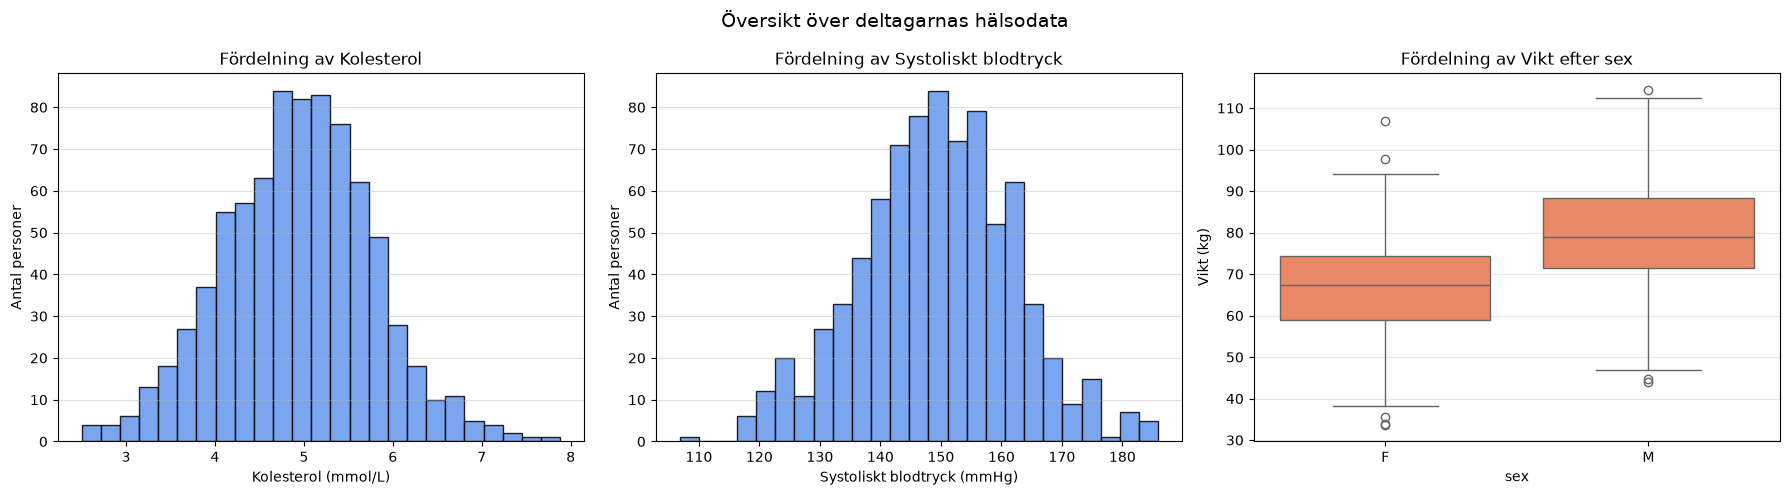

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

plot_distribution(df,"cholesterol", axes[0])
plot_distribution(df,"systolic_bp", axes[1])
plot_group_comparison(df, "weight", "sex", axes[2])

fig.suptitle("Översikt över deltagarnas hälsodata", fontsize=14)
plt.tight_layout()
plt.show()

**Tolkning** 
- Kolesterol är ungefär normalfördelat, med flest värden kring 4,5–5,5 mmol/L.
- Blodtrycket är ungefär normalfördelat, med flest värden kring 145–155 mmHg.
- Män har generellt högre vikt än kvinnor, och båda grupperna har några avvikande värden.
- Majoriteten av deltagarna är icke-rökare (cirka 73 %), medan cirka 27 % är rökare.

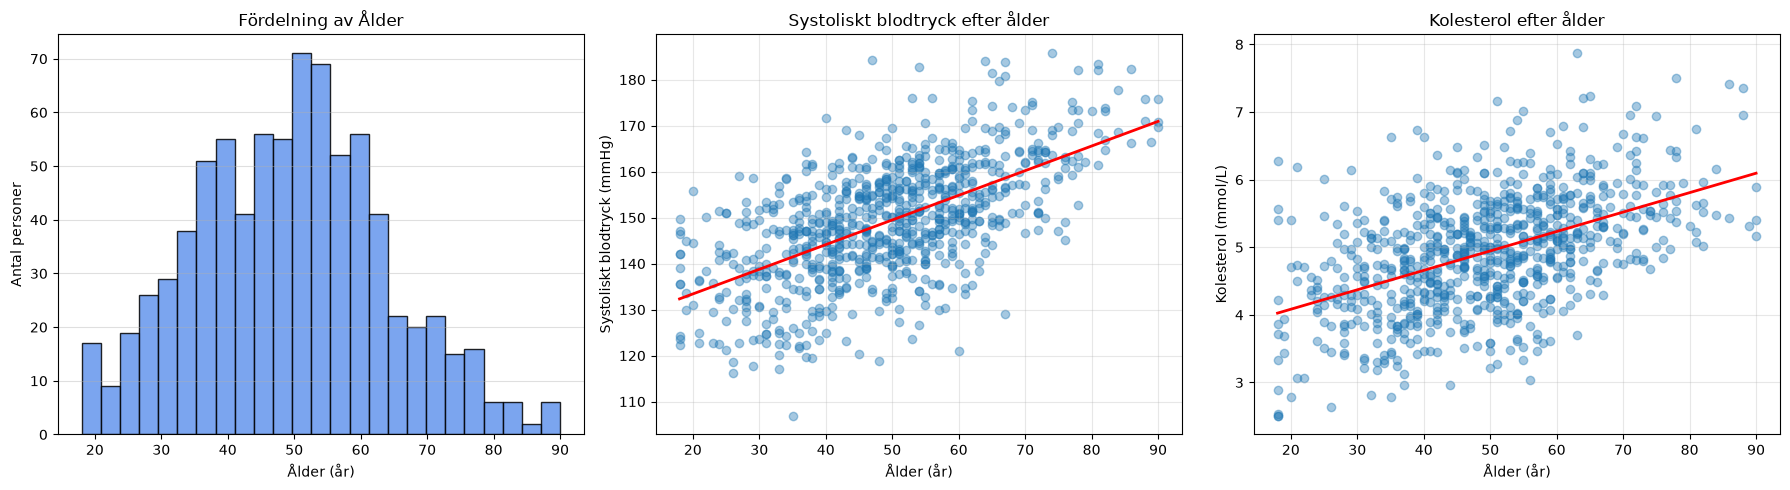

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


plot_distribution(df, "age", axes[0])
plot_relationship(df, "age", "systolic_bp", axes[1])
plot_relationship(df, "age","cholesterol", axes[2])

plt.tight_layout()
plt.show()


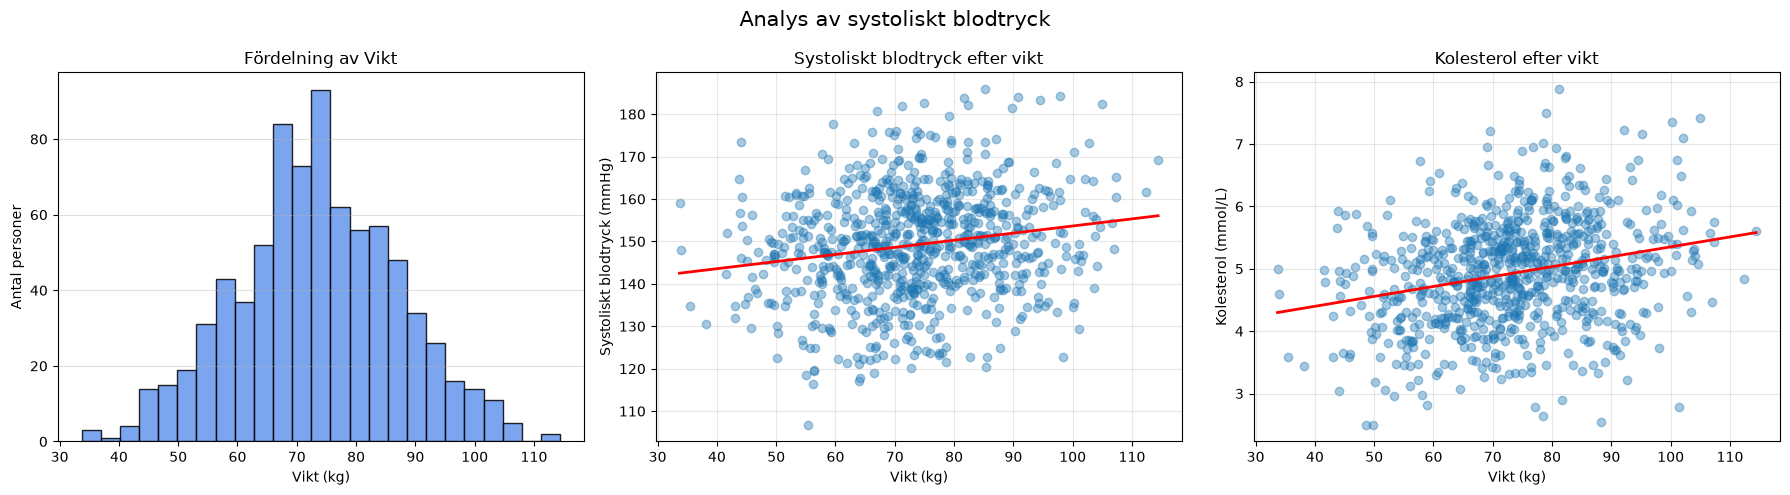

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))


plot_distribution(df, "weight", axes[0])
plot_relationship(df, "weight", "systolic_bp", axes[1])
plot_relationship(df, "weight","cholesterol", axes[2])
fig.suptitle("Analys av systoliskt blodtryck", fontsize=15)

plt.tight_layout()
plt.show()


**Tolkning:**

Ålders- och viktfördelningarna är ungefär normalfördelade.
Flest deltagare är kring 50–55 år och väger mellan 65 och 80 kg.

Det finns ett positivt samband mellan ålder och systoliskt blodtryck
samt mellan ålder och kolesterol. Både blodtrycket och kolesterolnivån
tenderar att öka med stigande ålder.

Det finns även svaga positiva samband mellan vikt och systoliskt
blodtryck samt mellan vikt och kolesterol. Både blodtrycket och
kolesterolnivån tenderar att öka något med stigande vikt.

Samtliga trendlinjer visar en uppåtgående trend, men det finns
variation mellan individerna. Sambanden med ålder framstår visuellt
som starkare än motsvarande samband med vikt.

Sambanden innebär inte nödvändigtvis orsakssamband.
Sambandens styrka kan undersökas vidare med hjälp av
korrelationsanalys och linjär regression.

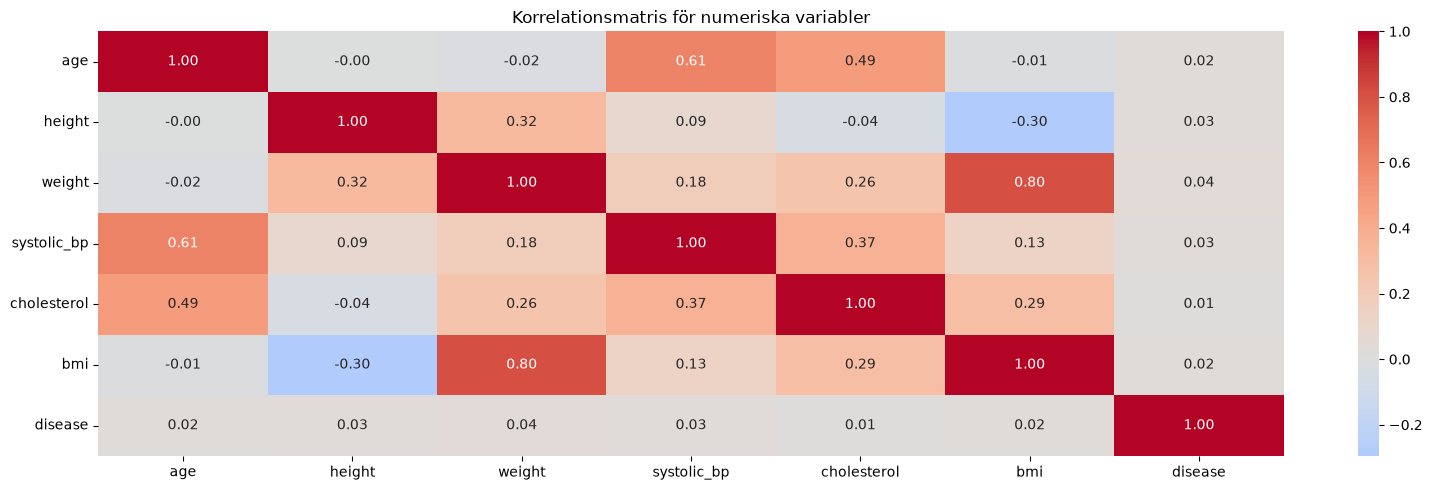

In [9]:
# Korrelationsheatmap för numeriska variabler

corr_matrix = analyzer.correlation()
plot_correlation_matrix(corr_matrix)


**Tolkning:** Ålder har ett relativt starkt positivt samband med systoliskt blodtryck (r = 0.61)
och ett måttligt samband med kolesterol (r = 0.49).

Blodtryck och kolesterol har också ett måttligt positivt samband (r = 0.37).
Sjukdom (disease) visar mycket svaga linjära samband med samtliga numeriska variabler
(r = 0.01–0.04).

Ålder, blodtryck och kolesterol visar tydliga samband med varandra,
medan ingen tydlig linjär korrelation med sjukdom kan observeras.
Korrelation innebär inte orsakssamband.


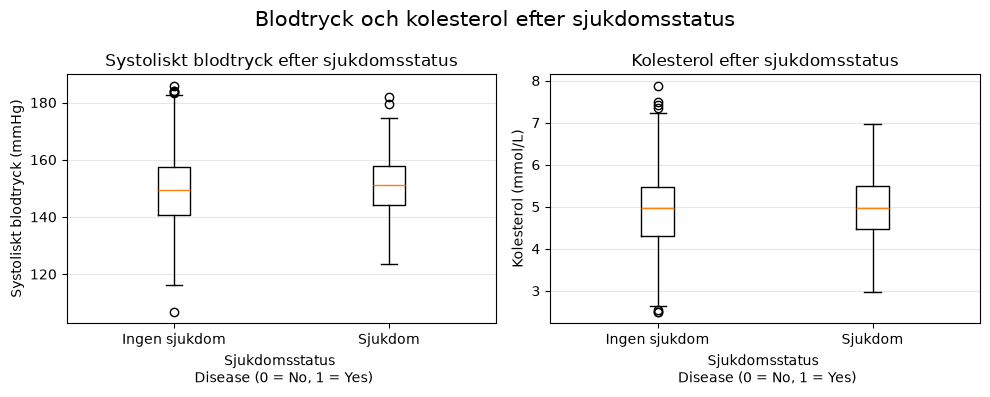

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

# Blodtryck efter sjukdomsstatus
plot_disease_boxplot(df, "systolic_bp", axes[0])

# Kolesterol efter sjukdomsstatus
plot_disease_boxplot(df, "cholesterol", axes[1])

fig.suptitle(
    "Blodtryck och kolesterol efter sjukdomsstatus",
    fontsize=15
)

plt.tight_layout()
plt.show()

**Tolkning:**
Det systoliska blodtrycket har en något högre median hos personer
med sjukdom (cirka 151 mmHg) jämfört med personer utan sjukdom
(cirka 149 mmHg). Fördelningarna överlappar dock tydligt.

Kolesterolnivåerna har nästan samma median (cirka 5,0)
i båda grupperna, med liknande spridning.

Det förekommer några avvikande värden i båda diagrammen.

Diagrammen visar endast små skillnader i blodtryck och kolesterol
mellan personer med och utan sjukdom.

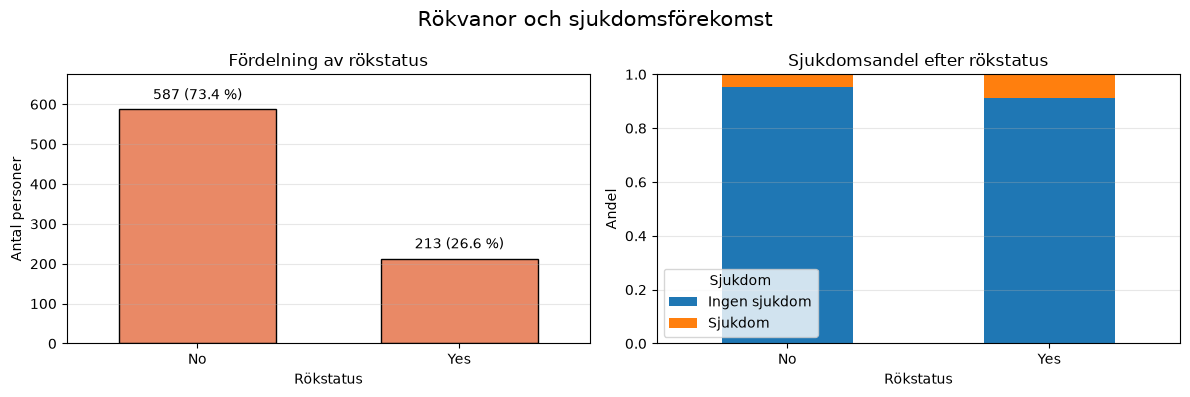

Antal     Andel (%)     
disease     0   1         0    1
smoker                          
No        559  28      95.2  4.8
Yes       194  19      91.1  8.9

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Antal och procent rökare
plot_smoking_distribution(df, axes[0])

# Sjukdomsandel efter rökstatus
plot_smoking_disease(df, axes[1])

fig.suptitle(
    "Rökvanor och sjukdomsförekomst",
    fontsize=15
)

plt.tight_layout()
plt.show()

# Antal personer
antal = pd.crosstab(df["smoker"], df["disease"])

# Andel i procent inom varje rökgrupp
andel = pd.crosstab(
    df["smoker"],
    df["disease"],
    normalize="index"
) * 100


smoking_disease_table = pd.concat(
    {"Antal": antal, "Andel (%)": andel},
    axis=1
)

display(smoking_disease_table.round(1))

**Tolkning:**
Andelen personer med sjukdom är något högre bland rökare
(cirka 9 %) än bland icke-rökare (cirka 5 %).

Majoriteten av deltagarna i båda grupperna har inte sjukdomen.

Diagrammet visar en skillnad på cirka 4 procentenheter
i sjukdomsandel mellan rökare och icke-rökare.

Det finns ett observerat samband mellan rökstatus och sjukdomsandel.
Ett statistiskt test, exempelvis ett z-test för två proportioner,
behövs för att undersöka om skillnaden är statistiskt signifikant.
Sambandet innebär inte att rökning orsakar sjukdomen.


## 5. Simulering – sjukdomsförekomst

Först beräknas den observerade andelen med sjukdomen. Därefter simuleras 1 000 oberoende personer med samma sannolikhet för sjukdom som i datasetet.

Simuleringen visar hur mycket andelen kan variera i ett slumpmässigt stickprov av 1 000 personer.

Här använder den observerade sjukdomsandelen som sannolikhet i en binomialmodell.


Verklig sjukdomsandel: 5.88%
Simulerad sjukdomsandel: 5.60%
Skillnad: 0.27%



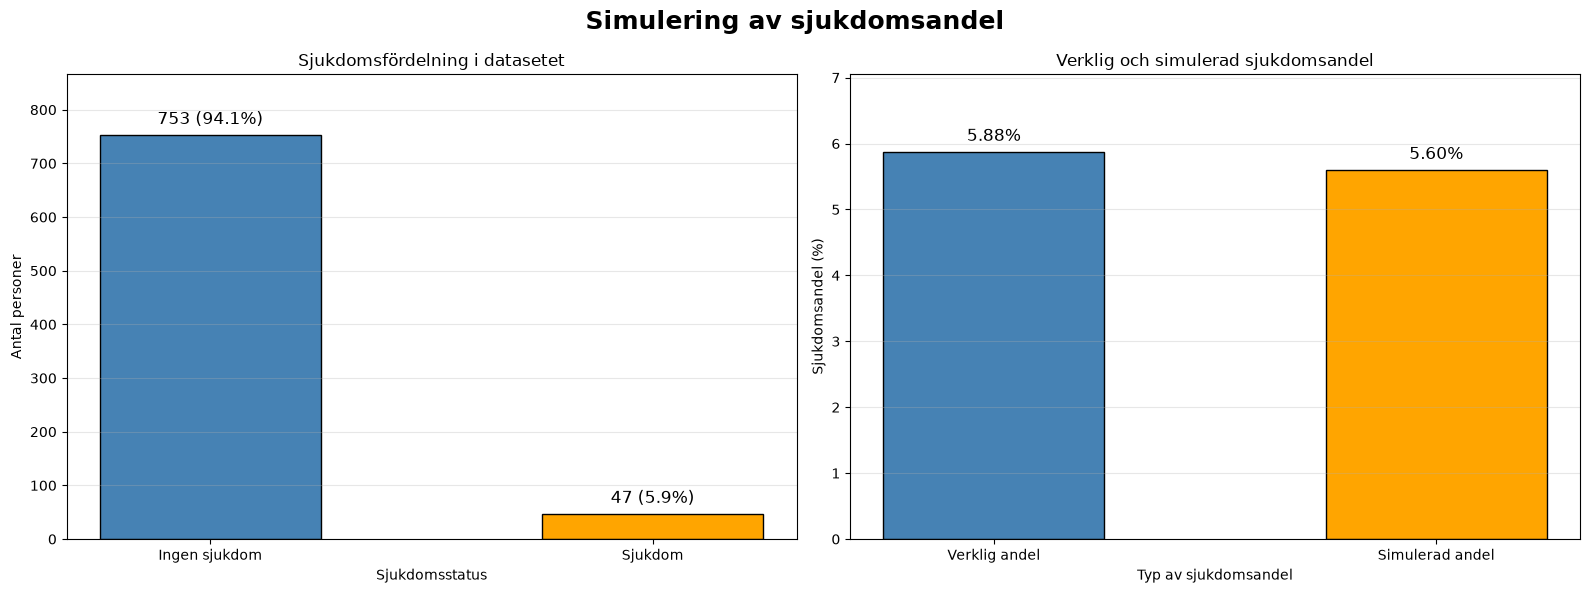

In [12]:
# Simulera sjukdomsförekomst
simulation, disease_percent, simulated_percentage, difference = (
    simulate_disease(df, n=1000, seed=42)
)

# Visa resultat
print(f"""
Verklig sjukdomsandel: {disease_percent:.2%}
Simulerad sjukdomsandel: {simulated_percentage:.2%}
Skillnad: {difference:.2%}
""")

fig = plot_disease_simulation(df, simulation)

plt.show()


**Tolkning:**
Av 800 deltagare har 5,88 % sjukdomen.
Den simulerade andelen är 5,60 %, vilket ligger nära den verkliga.
Skillnaden på 0,28 procentenheter visar slumpmässig variation.

## 6. Konfidensintervall för medelvärdet av systoliskt blodtryck

Ett 95-procentigt konfidensintervall beskriver en metods osäkerhet vid skattning av populationsmedelvärdet. I upprepade stickprov skulle cirka 95 % av intervallen täcka det sanna medelvärdet, om metodens antaganden är uppfyllda.

Vi jämför:
1. **Normal approximation:** 
2. **Bootstrap:** 

Metodval: Skattar  först medelblodtrycket med normalapproximation och jämför sedan med ett bootstrapintervall. Båda använder samma ursprungliga observationer och är inte två oberoende studier.


-------------------Normalapproximation Methoden---------------------------

Antal observationer                 : 800
Medelvärde för systoliskt blodtryck : 149.18
Stickprovsstandardavvikelse         : 12.79
Standardfel                         : 0.45
95 % Z-konfidensintervall           : (148.29, 150.07)

--------------------------Bootstrap Methoden-------------------------------
Bootstrap-medelvärde                : 149.19
Bootstrap-standardfel               : 0.45
95 % Bootstrap-konfidensintervall   : (148.29, 150.06)




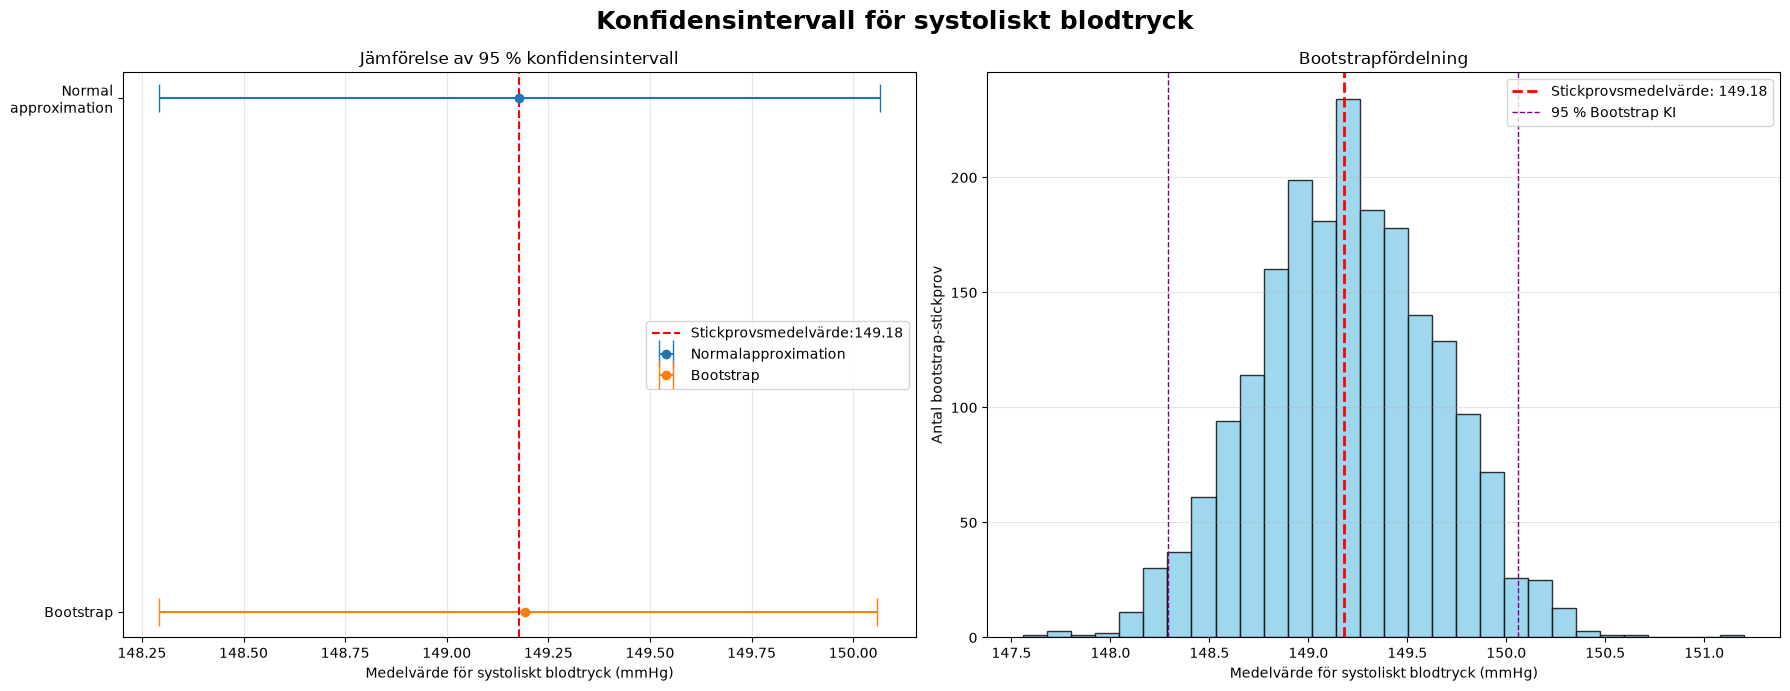

In [13]:

# Beräkna konfidensintervall
bp_ci, bp_boot = analyzer.bp_confidence_intervals(B=2000, seed=SEED)

lower, upper, mean, s, SE, n = bp_ci
boot_means, ci_boot_lower, ci_boot_upper = bp_boot


print(f"""-------------------Normalapproximation Methoden---------------------------

Antal observationer                 : {n}
Medelvärde för systoliskt blodtryck : {mean:.2f}
Stickprovsstandardavvikelse         : {s:.2f}
Standardfel                         : {SE:.2f}
95 % Z-konfidensintervall           : ({lower:.2f}, {upper:.2f})

--------------------------Bootstrap Methoden-------------------------------
Bootstrap-medelvärde                : {np.mean(boot_means):.2f}
Bootstrap-standardfel               : {np.std(boot_means, ddof=1):.2f}
95 % Bootstrap-konfidensintervall   : ({ci_boot_lower:.2f}, {ci_boot_upper:.2f})

""")


# visualisering Confidence interval 


fig = plot_bootstrap_ci(
    normal=bp_ci,
    bootstrap=bp_boot,
    title="Konfidensintervall för systoliskt blodtryck",
    xlabel="Medelvärde för systoliskt blodtryck (mmHg)",
    unit="mmHg"
)

plt.show()

**Tolkning:**
Det genomsnittliga systoliska blodtrycket är 149,18 mmHg.
Både normalapproximation och bootstrap ger liknande
95 % konfidensintervall, cirka 148,3–150,1 mmHg.

Bootstrapfördelningen är ungefär normalfördelad och
centrerad kring stickprovsmedelvärdet.

Slutsats:
Metoderna ger liknande skattningar, vilket tyder på
att uppskattningen av medelblodtrycket är stabil.

## 7. Hypotesprövning – rökare och blodtryck

**Fråga:** Har rökare högre genomsnittligt systoliskt blodtryck än icke-rökare?

Vi använder ett ensidigt Welch t-test för två oberoende grupper.

- H0: μ_rökare ≤ μ_icke-rökare
- H1: μ_rökare > μ_icke-rökare

Signifikansnivå: α = 0,05.

**Metodval**: Welch-testet jämför två oberoende gruppers medelvärden utan att anta lika varians. Testet är ensidigt eftersom den fördefinierade frågan gäller högre blodtryck hos rökare. Ett tvåsidigt 95 %-intervall redovisas separat för att visa rimliga skillnader i båda riktningar. Cohen’s d beskriver skillnaden i standardavvikelseenheter.



-------Rökare-------
Antal                                       : 213
Medelvärde                                  : 149.52
--------Icke-rökare---------
Antal                                       : 587
Medelvärde                                  : 149.05

---------Jämförelse----------
Skillnad mean mellan rökare och icke-rökare : 0.47 mmHg
t-statistik                                 : 0.4503
p-värde (ensidigt)                          : 0.3264
------- 95 % konfidensintervall -------
Nedre gräns                                 : -1.59
Övre gräns                                  : 2.53


Ensidig 95 % nedre konfidensgräns: [-1.26, +∞) mmHg")

Cohen's d: 0.037


Beslut: Förkasta inte H0. Det finns inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck.


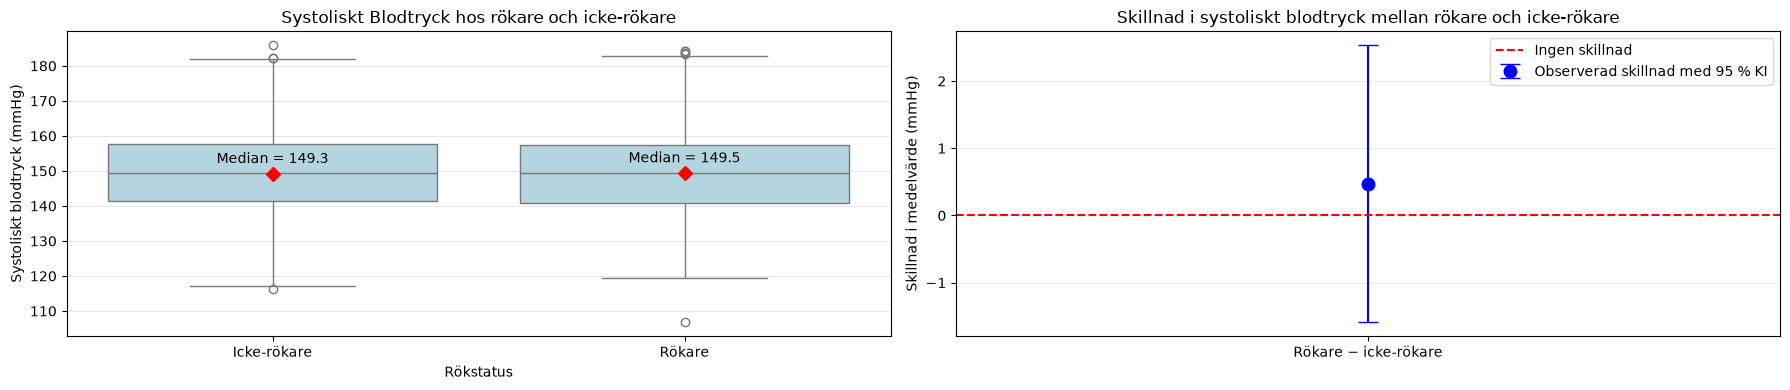

In [29]:
summary = analyzer.smoking_summary()
test = analyzer.smoking_bp_test()

print(f"""
-------Rökare-------
Antal                                       : {test['n_a']}
Medelvärde                                  : {test['mean_a']:.2f}
--------Icke-rökare---------
Antal                                       : {test['n_b']}
Medelvärde                                  : {test['mean_b']:.2f}

---------Jämförelse----------
Skillnad mean mellan rökare och icke-rökare : {test['observed_skillnad']:.2f} mmHg
t-statistik                                 : {test['statistic']:.4f}
p-värde (ensidigt)                          : {test['pvalue']:.4f}
------- 95 % konfidensintervall -------
Nedre gräns                                 : {test['lower']:.2f}
Övre gräns                                  : {test['upper']:.2f}


Ensidig 95 % nedre konfidensgräns: [{test['ci_one_lower']:.2f}, +∞) mmHg")

Cohen's d: {test['cohens_d']:.3f}
""")

if test["pvalue"]< 0.05:
    print("\nBeslut: Förkasta H0. Resultatet ger statistiskt stöd för högre medelblodtryck bland rökare.")
else:
    print("\nBeslut: Förkasta inte H0. Det finns inte tillräckligt statistiskt stöd för att rökare har högre medelblodtryck.")


fig = plot_smoking_bp(df, test)
plt.show()


**Tolkning – Skillnad i medelblodtryck mellan rökare och icke-rökare**
Diagrammet visar ingen tydlig skillnad i blodtryck
mellan grupperna. Ett Welch's t-test används för att undersöka
om skillnaden i medelblodtryck är statistiskt signifikant.

Rökare har ett något högre medelblodtryck än icke-rökare, med en observerad skillnad på cirka **0,47 mmHg**.

95 % konfidensintervallet sträcker sig ungefär från **−1,6 till 2,5 mmHg** och inkluderar noll.

Skillnaden är liten och inte statistiskt signifikant på 5 %-nivån vid ett motsvarande tvåsidigt test. Det finns inte tillräckligt med statistiskt stöd för att medelblodtrycket skiljer sig mellan grupperna..

## 8. Poweranalys

Power är sannolikheten att ett test förkastar nollhypotesen när en viss alternativhypotes faktiskt är sann.


Simuleringen antar ungefär normalfördelade blodtryck inom grupperna, använder observerade gruppstorlekar och gruppstandardavvikelser. Vi gör många Welch-test och räknar andelen p-värden under 0,05.

Vi undersöker hur ofta samma test skulle upptäcka olika antagna skillnader med samma gruppstorlekar och ungefär samma spridning. Power beräknad från den observerade effekten är inte ett mått på sannolikheten att nollhypotesen är sann.

Observerad skillnad: 0.47 mmHg

------------ Observerad skillnad ------------
Antagen skillnad  : 0.47 mmHg
Uppskattad power  : 0.106
Power i procent   : 10.6 %

------------ Antagen skillnad (2 mmHg) ------------
Antagen skillnad  : 2.00 mmHg
Uppskattad power  : 0.592
Power i procent   : 59.2 %

------------ Antagen skillnad (5 mmHg) ------------
Antagen skillnad  : 5.00 mmHg
Uppskattad power  : 0.999
Power i procent   : 99.9 %

------------ Antagen skillnad (8 mmHg) ------------
Antagen skillnad  : 8.00 mmHg
Uppskattad power  : 1.000
Power i procent   : 100.0 %


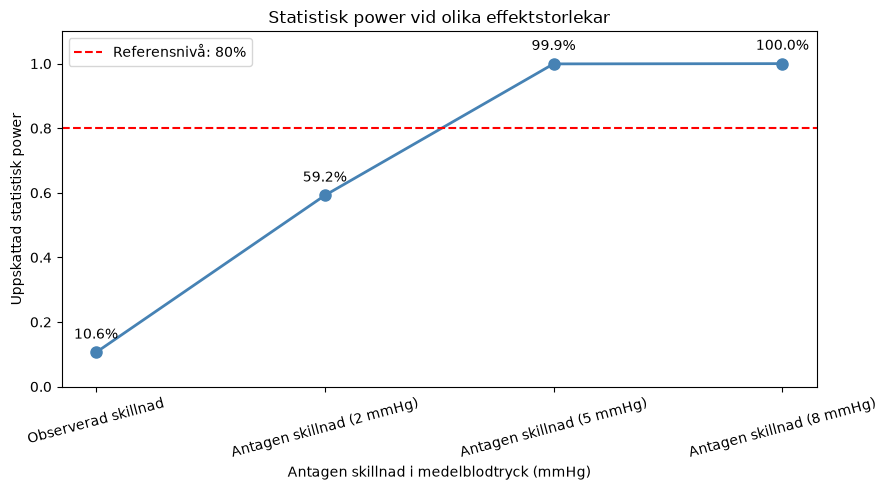

In [15]:
smokers = df.loc[df["smoker"] == "Yes", "systolic_bp"].dropna()
non_smokers = df.loc[df["smoker"] == "No", "systolic_bp"].dropna()

# Beräkna observerad skillnad
observed_effect = smokers.mean() - non_smokers.mean()

print(f"Observerad skillnad: {observed_effect:.2f} mmHg")

# Definiera olika scenarier
effects = {
    "Observerad skillnad": observed_effect,
    "Antagen skillnad (2 mmHg)": 2.0,
    "Antagen skillnad (5 mmHg)": 5.0,
    "Antagen skillnad (8 mmHg)": 8.0
}

power_result = {}

# Kör simuleringen för varje scenario
for i, (name, assumed_effect) in enumerate(effects.items()):

    power = simulated_power(
        smokers=smokers,
        non_smokers=non_smokers,
        vald_effekt=assumed_effect,
        n_simulations=5000,
        alpha=0.05,
        seed=42 + i
    )

    power_result[name] = power

    print(f"\n------------ {name} ------------")
    print(f"Antagen skillnad  : {assumed_effect:.2f} mmHg")
    print(f"Uppskattad power  : {power:.3f}")
    print(f"Power i procent   : {power * 100:.1f} %")

fig = plot_power_curve(
    power_result,
    title="Statistisk power vid olika effektstorlekar",
    xlabel="Antagen skillnad i medelblodtryck (mmHg)"
)

plt.show()

**Tolkning – Statistisk power vid olika effektstorlekar**

Den observerade skillnaden (0,47 mmHg) har låg statistisk power, cirka **10 %**.

Vid en antagen skillnad på **2 mmHg** ökar power till cirka **59 %**, men når inte målnivån på 80 %.

Vid större skillnader (5 och 8 mmHg) är power nästan **100 %**.

**Slutsats:** Studien har låg förmåga att upptäcka små skillnader i blodtryck, men hög förmåga att upptäcka större skillnader. Ett större stickprov kan behövas för att upptäcka små effekter med tillräcklig power.

## 9. Linjär regression

**Analysfråga:** Kan systoliskt blodtryck förutsägas utifrån
ålder, och förbättras prognosen när vikt, kolesterol och
rökstatus inkluderas i en multipel regressionsmodell?

**Metod:**

Datasetet delas upp i 80 % träningsdata och 20 % testdata,
med slumpfrö 42 för att säkerställa reproducerbarhet.

- **Enkel linjär regression:** Ålder → systoliskt blodtryck.
- **Multipel linjär regression:** Ålder, vikt, kolesterol
  och rökstatus → systoliskt blodtryck.

Rökstatus kodas numeriskt, där 0 representerar icke-rökare
och 1 representerar rökare.

**Utvärdering av modellerna:**

- **R²:** Används för att bedöma modellens förklaringsgrad.
- **MAE:** Används för att mäta det genomsnittliga absoluta
  prediktionsfelet i mmHg.
- **RMSE:** Används för att mäta prediktionsfelet med större
  vikt på stora avvikelser.

Utöver R², som behandlats under kursen, används MAE och RMSE
som kompletterande utvärderingsmått för att få en bättre
förståelse av modellernas prediktionsförmåga och felmarginaler.

Regression används i explorativt och prediktivt syfte,
inte för klinisk riskbedömning. Resultaten innebär inte
nödvändigtvis orsakssamband.

### 9.1 Enkel linjär regression


Syftet är att undersöka sambandet mellan ålder och
systoliskt blodtryck samt att utvärdera modellens
förmåga att förutsäga blodtryck utifrån ålder.

- Förklarande variabel (X): Ålder
- Responsvariabel (y): Systoliskt blodtryck

Modellen tränas med minsta kvadratmetoden (OLS)
med hjälp av Scikit-learn.

Intercept: 123.1409
Lutning: 0.5241
R²: 0.3952
MAE: 7.7481 mmHg
RMSE: 9.9758 mmHg


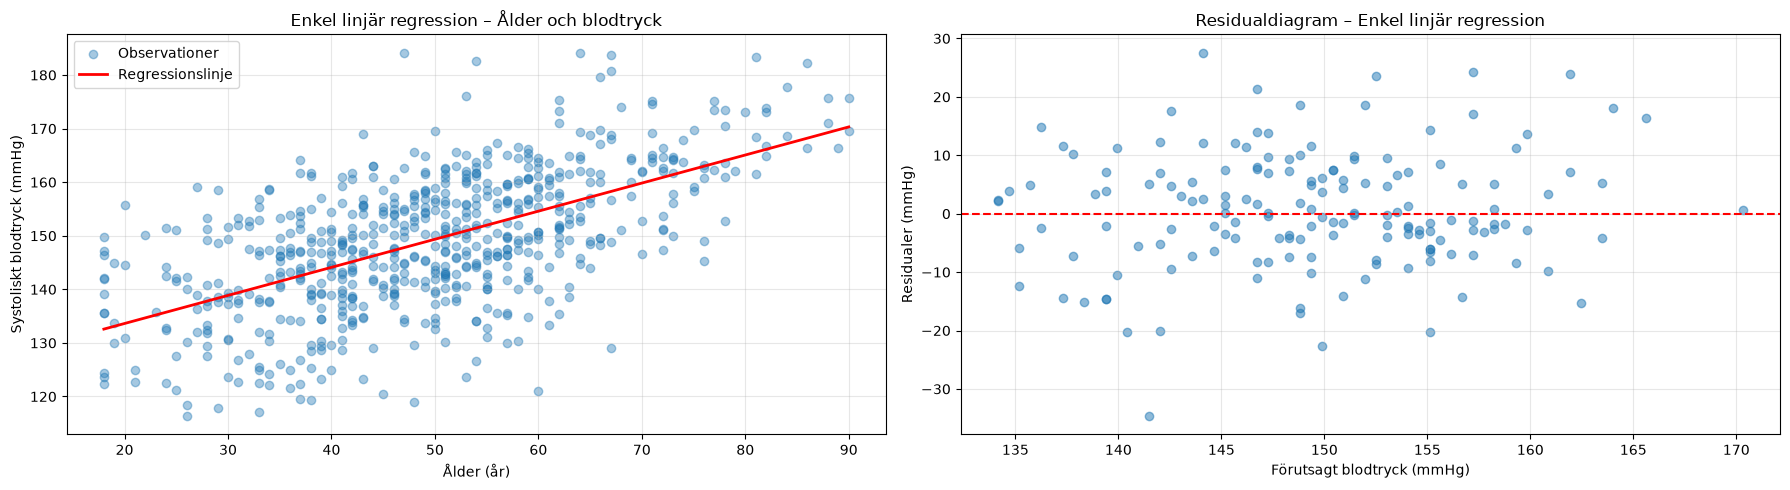

interactive(children=(IntSlider(value=50, continuous_update=False, description='Ålder:', max=90, min=18), Outp…

In [17]:
linreg = analyzer.regression(
    features=["age"],
    target="systolic_bp"
)

linreg_model = linreg["model"]

print(f"Intercept: {linreg_model.intercept_:.4f}")
print(f"Lutning: {linreg_model.coef_[0]:.4f}")

print(f"R²: {linreg['r2']:.4f}")
print(f"MAE: {linreg['mae']:.4f} mmHg")
print(f"RMSE: {linreg['rmse']:.4f} mmHg")

plot_simple_regression(linreg)

plot_interactive_simple(linreg)

**Tolkning:**

Regressionslinjen visar ett positivt samband mellan ålder och
systoliskt blodtryck.

- **Intercept (123,14):** Modellens uppskattade blodtryck vid
  0 års ålder. Värdet har ingen praktisk betydelse i denna studie.

- **Lutning (0,5241):** Det förutsagda systoliska blodtrycket ökar
  med cirka 0,52 mmHg per ytterligare levnadsår, vilket motsvarar
  cirka 5,24 mmHg per tio år.

- **R² (0,3952):** Modellen förklarar cirka 39,5 % av variationen
  i systoliskt blodtryck i testdata.

- **MAE (7,75 mmHg):** Modellens prediktioner avviker i genomsnitt
  med cirka 7,75 mmHg från de faktiska blodtrycksvärdena.

- **RMSE (9,98 mmHg):** Prediktionsfelet är cirka 9,98 mmHg när
  större avvikelser ges större vikt.

**Residualanalys:**

Residualerna är relativt jämnt fördelade kring nollinjen utan
något tydligt systematiskt mönster. Detta tyder på att en linjär
modell är rimlig, även om större prediktionsfel förekommer.

**Interaktiv prognos:**

För en person som är 50 år förutsäger modellen ett systoliskt
blodtryck på cirka 149,3 mmHg.

Det genomsnittliga absoluta prediktionsfelet (7,75 mmHg) är
större än den förutsagda skillnaden mellan två personer med
tio års åldersskillnad (5,24 mmHg).

**Slutsats:**

Ålder har ett tydligt positivt samband med systoliskt blodtryck,
men ålder ensam har begränsad förmåga att förutsäga individuella
blodtrycksvärden.

Det är därför relevant att undersöka om vikt, kolesterol och
rökstatus kan förbättra modellens prediktionsförmåga genom
multipel linjär regression.

### 9.2 Multipel linjär regression

Syftet är att undersöka sambandet mellan systoliskt blodtryck och flera förklarande variabler. Multipel linjär regression bygger på matriser och
vektorer.

De förklarande variablerna representeras av en
designmatris X och responsvariabeln av en vektor y.

Förklarande variabler (X):

- Ålder
- Vikt
- Kolesterol
- Rökstatus (0 = icke-rökare, 1 = rökare)

Responsvariabel (y):

- Systoliskt blodtryck

Scikit-learn använder minsta kvadratmetoden för att
skatta regressionskoefficienterna genom att minimera
summan av de kvadrerade residualerna.

Den tränade modellen används sedan för att beräkna
prediktioner för nya observationer.

Intercept: 108.1194
R²: 0.4178
MAE: 7.6664 mmHg
RMSE: 9.7869 mmHg


,Variabel,Koefficient
0,age,0.5083
1,weight,0.1687
2,cholesterol,0.6635
3,smoker_numeric,0.4610


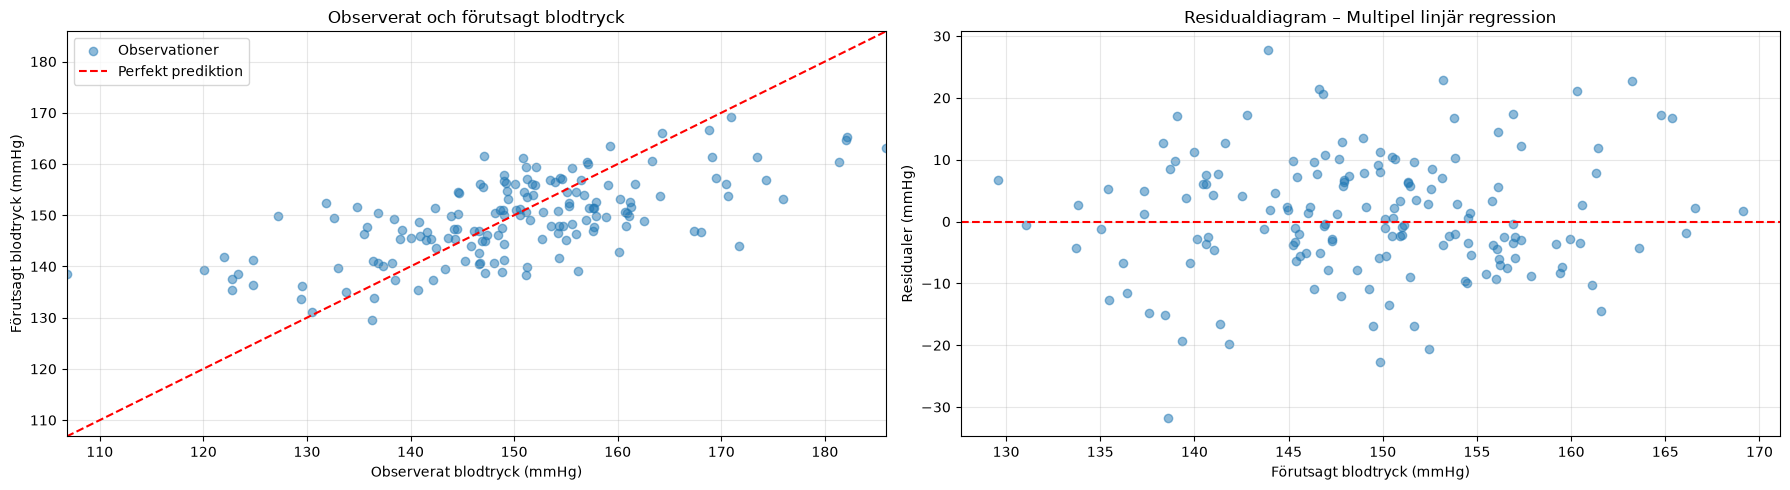

interactive(children=(IntSlider(value=50, continuous_update=False, description='Ålder:', max=90, min=18), Floa…

In [18]:
multiple = analyzer.regression(
    features=[
        "age",
        "weight",
        "cholesterol",
        "smoker_numeric"
    ],
    target="systolic_bp"
)

multiple_model = multiple["model"]

print(f"Intercept: {multiple_model.intercept_:.4f}")

print(f"R²: {multiple['r2']:.4f}")
print(f"MAE: {multiple['mae']:.4f} mmHg")
print(f"RMSE: {multiple['rmse']:.4f} mmHg")

#Regressionskoefficienter
coefficients = pd.DataFrame({
    "Variabel": multiple["features"],
    "Koefficient": multiple_model.coef_
})

display(coefficients.round(4))

plot_multiple_regression(multiple)

plot_interactive_multiple(multiple)

**Tolkning:**

Den multipla regressionsmodellen visar positiva samband mellan
ålder, vikt, kolesterol, rökstatus och systoliskt blodtryck,
när övriga variabler hålls konstanta.

Modellen förklarar cirka 41,8 % av variationen i blodtrycket
(R² = 0,4178). MAE är 7,67 mmHg och RMSE är 9,79 mmHg.

Modellen tenderar att överskatta låga blodtrycksvärden och
underskatta höga blodtrycksvärden. Residualerna är relativt
jämnt fördelade kring nollinjen utan tydliga systematiska mönster.

Jämfört med enkel linjär regression har den multipla modellen
något högre förklaringsgrad och lägre prediktionsfel.
Förbättringen är dock relativt liten.

Sambanden innebär inte nödvändigtvis orsakssamband.

### 9.3 Jämförelse av regressionsmodeller

In [19]:
# Skapa en jämförelsetabell för regressionsmodellerna
comparison = pd.DataFrame({
    "Utvärderingsmått": ["R²", "MAE (mmHg)", "RMSE (mmHg)"],
    "Enkel regression": [0.3952, 7.7481, 9.9758],
    "Multipel regression": [0.4178, 7.6664, 9.7869]
})

# Beräkna förändringen mellan modellerna
comparison["Förändring"] = (
    comparison["Multipel regression"] -
    comparison["Enkel regression"]
)

display(comparison.round(4))

,Utvärderingsmått,Enkel regression,Multipel regression,Förändring
0,R²,0.3952,0.4178,0.0226
1,MAE (mmHg),7.7481,7.6664,-0.0817
2,RMSE (mmHg),9.9758,9.7869,-0.1889


**Slutsats:**

Den multipla regressionsmodellen har något högre förklaringsgrad
och lägre prediktionsfel än den enkla modellen. Förklaringsgraden
ökar från 39,52 % till 41,78 %, vilket motsvarar en ökning
på 2,26 procentenheter.

Inkludering av vikt, kolesterol och rökstatus förbättrar
modellens prediktionsförmåga något, men förbättringen är
relativt liten.

Ålder framstår som en viktig förklarande variabel, men en stor
del av variationen i systoliskt blodtryck förklaras fortfarande
inte av modellerna.

Modellerna kan användas för att undersöka statistiska samband
och göra uppskattningar, men inte för klinisk riskbedömning.

## Kompletterande analys – sjukdomsandel bland rökare och icke-rökare


## 1. Beskrivande statistik – Sjukdomsandel

Syftet är att undersöka om sjukdomsandelen skiljer sig mellan
rökare och icke-rökare.

- Oberoende variabel: smoker (Yes/No)
- Beroende variabel: disease (0/1)

Här beräknar antal observationer, antal sjukdomsfall och
sjukdomsandel för respektive grupp.

In [20]:

alpha = 0.05
np.random.seed(42)

# Funktion för procentformatering
def pct(x):
    return f"{x * 100:.1f}%"

# Sammanfatta sjukdomsandel per grupp
display(analyzer.disease_groups().round(4))

,observations,disease_cases,disease_proportion
smoker,,,
No,587,28,0.0477
Yes,213,19,0.0892


## 2. Konfidensintervall och hypotesprövning

Fråga: Skiljer sig andelen med sjukdom mellan rökare och icke-rökare? Detta är en separat explorativ analys.
- H₀: Andelen med sjukdom är lika i båda grupperna.
- H₁: Andelarna skiljer sig (tvåsidigt).

Metoder:
- Wilsons 95 % konfidensintervall för varje grupp
- Ensidigt z-test för två proportioner
- 95 % konfidensintervall för skillnaden (Newcombe)
- Absolut och relativ skillnad

In [21]:
#Confidence intervals and hypothesis test

disease_test = analyzer.smoking_disease_test()


# Sammanfattning
conclusion = f"""
------------ SJUKDOMSANDEL ------------

Icke-rökare (A)

Antal                    :{disease_test['n_A']}
Sjukdomsfall             :{disease_test['x_A']}
Andel                    :{pct(disease_test['p_A'])}
95 % KI                  :[{pct(disease_test['ci_A'][0])}, {pct(disease_test['ci_A'][1])}]

Rökare (B)

Antal                    :{disease_test['n_B']}
Sjukdomsfall             :{disease_test['x_B']}
Andel                    :{pct(disease_test['p_B'])}
95 % KI                  :[{pct(disease_test['ci_B'][0])}, {pct(disease_test['ci_B'][1])}]

------------ JÄMFÖRELSE ------------

Absolut lift (B - A)     :{disease_test['absolute_pp']:.2f} procentenheter
Relativ lift             :{disease_test['relative_lift']:.1f} %


95 % KI för skillnaden   :[{disease_test['lower']*100:.2f}, {disease_test['upper']*100:.2f}] pp
Z-statistik              :{disease_test['statistic']:.4f}
Tvåsidigt p-värde        :{disease_test['p_two_sided']:.4f}
Ensidigt p-värde (B > A) :{disease_test['p_one_sided']:.4f}
"""
print(conclusion)

if disease_test["p_one_sided"] < alpha:
    print("Beslut: Förkasta H0.")
    print("Rökare har statistiskt signifikant högre sjukdomsandel.\n")
else:
    print("Beslut: Kan inte förkasta H0.")
    print("Otillräckligt stöd för högre sjukdomsandel bland rökare.\n")


------------ SJUKDOMSANDEL ------------

Icke-rökare (A)

Antal                    :587
Sjukdomsfall             :28
Andel                    :4.8%
95 % KI                  :[3.3%, 6.8%]

Rökare (B)

Antal                    :213
Sjukdomsfall             :19
Andel                    :8.9%
95 % KI                  :[5.8%, 13.5%]

------------ JÄMFÖRELSE ------------

Absolut lift (B - A)     :4.15 procentenheter
Relativ lift             :87.0 %


95 % KI för skillnaden   :[0.41, 8.96] pp
Z-statistik              :2.2063
Tvåsidigt p-värde        :0.0274
Ensidigt p-värde (B > A) :0.0137

Beslut: Förkasta H0.
Rökare har statistiskt signifikant högre sjukdomsandel.



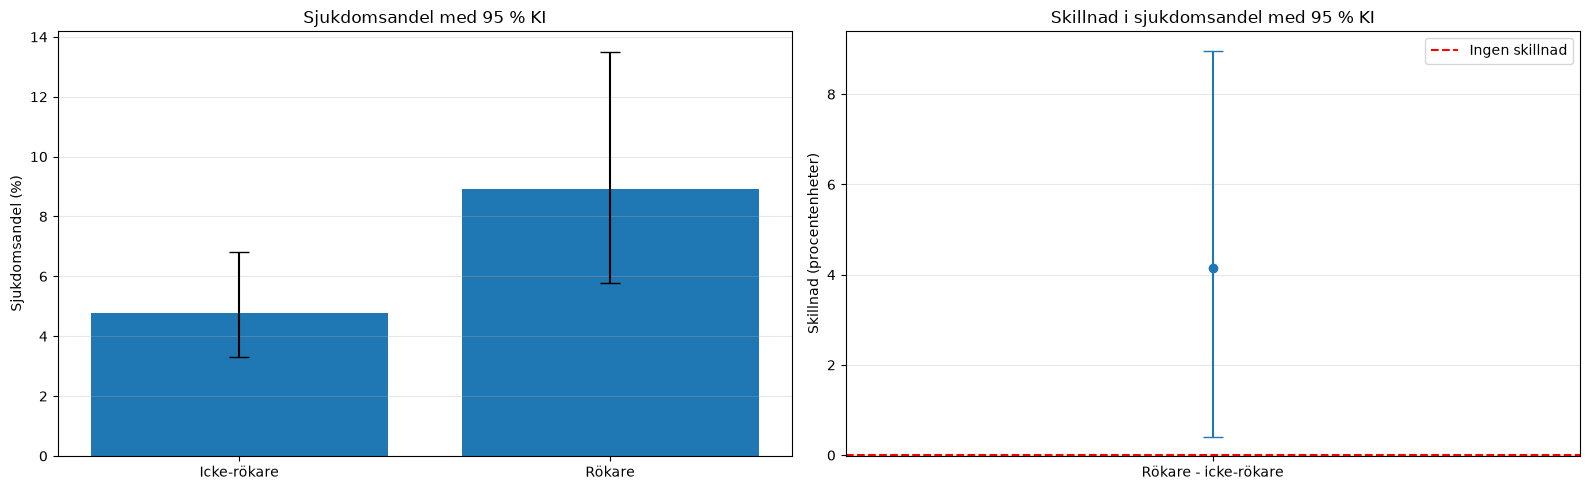

In [30]:
fig = plot_disease_proportion_ci(disease_test)
plt.show()

## 3. Power Analysis

In [23]:
analytical_result = analytical_power_proportions(
    p_A=disease_test["p_A"],
    p_B=disease_test["p_B"],
    n_A=disease_test["n_A"],
    n_B=disease_test["n_B"],
    alpha=0.05
)


effect_size = analytical_result["effect_size"]
power = analytical_result["power"]

power_summary = f"""

Effektstorlek (Cohen's h): {analytical_result["effect_size"]:.3f}
Signifikansnivå: {analytical_result["alpha"]}
Analytisk power: {pct(analytical_result["power"])}
"""

print(power_summary)



Effektstorlek (Cohen's h): 0.166
Signifikansnivå: 0.05
Analytisk power: 66.8%



## 4. Simulerad statistisk power

Här använder binomialfördelningen eftersom disease är
en binär variabel (0 eller 1).

Vi simulerar 5 000 nya studier med samma gruppstorlekar
och antagna sjukdomsandelar.

För varje simulering utförs ett ensidigt z-test.

Andelen signifikanta tester används som uppskattad power..


In [24]:

sim_power = simulated_power_proportions(
    p_A=disease_test["p_A"],
    p_B=disease_test["p_B"],
    n_A=disease_test["n_A"],
    n_B=disease_test["n_B"],
    n_simulations=5000,
    alpha=0.05,
    seed=42
)

simulation_summary = f"""
------------ POWERJÄMFÖRELSE ------------

Antal simuleringar        : 5000
Signifikansnivå           :{alpha}

Analytisk power           : {pct(power)}
Simulerad power           : {pct(sim_power)}
Skillnad mellan metoderna : {abs(sim_power-power)*100:.2f} pp
"""

print(simulation_summary)


------------ POWERJÄMFÖRELSE ------------

Antal simuleringar        : 5000
Signifikansnivå           :0.05

Analytisk power           : 66.8%
Simulerad power           : 67.9%
Skillnad mellan metoderna : 1.14 pp



## 5. Power vid olika antagna sjukdomsandelar

Här undersöker hur statistisk power förändras när
den antagna sjukdomsandelen bland rökare ökar.

Sjukdomsandelen bland icke-rökare hålls konstant.

Vi jämför:
- Ingen skillnad
- Liten skillnad
- Observerad skillnad
- Större skillnader

Syftet är att undersöka hur effektstorleken
påverkar sannolikheten att upptäcka en skillnad.

In [25]:
# Antagna sjukdomsandelar bland rökare
assumed_proportions = [disease_test["p_A"], 0.06, disease_test["p_B"], 0.12, 0.15]


power_results = simulated_power_curve(
    p_A=disease_test["p_A"],
    n_A=disease_test["n_A"],
    n_B=disease_test["n_B"],
    assumed_proportions=assumed_proportions,
    n_simulations=5000,
    alpha=0.05,
    seed=42
)

for row in power_results:

    print(
        f"Rökare: {row['proportion']:.1%} | "
        f"Skillnad: {row['effekt']*100:.2f} pp | "
        f"Power: {row['power']:.1%}"
    )


Rökare: 4.8% | Skillnad: 0.00 pp | Power: 5.5%
Rökare: 6.0% | Skillnad: 1.23 pp | Power: 17.8%
Rökare: 8.9% | Skillnad: 4.15 pp | Power: 67.9%
Rökare: 12.0% | Skillnad: 7.23 pp | Power: 96.4%
Rökare: 15.0% | Skillnad: 10.23 pp | Power: 99.7%


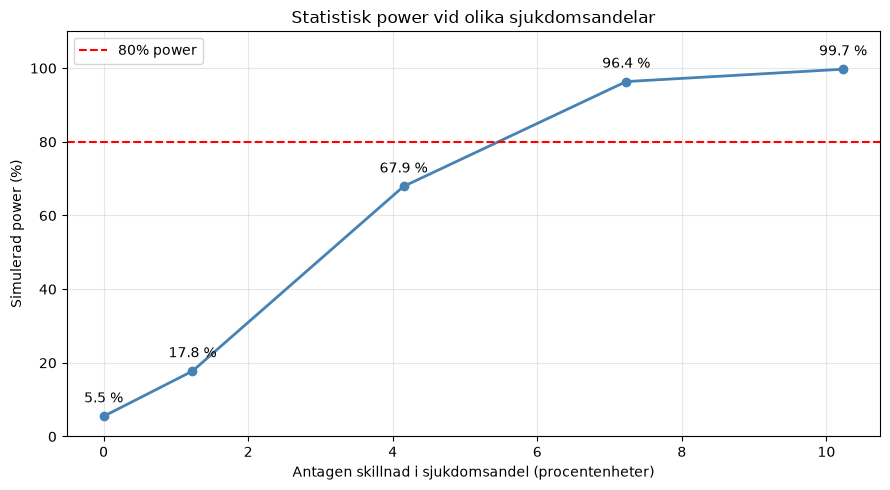

In [31]:
fig = plot_power_proportions(
    power_results,
    title="Statistisk power vid olika sjukdomsandelar",
    xlabel="Antagen skillnad i sjukdomsandel (procentenheter)",
    target_power=0.80
)

plt.show()

In [27]:
final_summary = f"""
========== HÄLSOSTUDIE: SLUTRESULTAT ==========

1. SJUKDOMSANDEL

Icke-rökare:       {pct(disease_test['p_A'])}
Rökare:            {pct(disease_test['p_B'])}

2. EFFEKT

Absolut lift:      {disease_test['absolute_pp']:.2f} procentenheter
Relativ lift:      {disease_test['relative_lift']:.1f} %

95 % KI:           [{disease_test['lower']*100:.2f}, {disease_test['upper']*100:.2f}] pp

3. HYPOTESPRÖVNING

Ensidigt p-värde:  {disease_test['p_one_sided']:.4f}
Tvåsidigt p-värde: {disease_test['p_two_sided']:.4f}
Signifikansnivå:   {alpha}

4. POWER

Cohen's h:         {analytical_result['effect_size']:.3f}
Analytisk power:   {pct(analytical_result['power'])}
Simulerad power:   {pct(sim_power)}

5. SLUTSATS

{"Statistiskt signifikant högre sjukdomsandel bland rökare."
 if disease_test['p_one_sided'] < alpha
 else "Ingen statistiskt säkerställd högre sjukdomsandel bland rökare."}

Poweranalysen visar hur känslig studien är för
olika antagna skillnader i sjukdomsandel.

================================================
"""

print(final_summary)


========== HÄLSOSTUDIE: SLUTRESULTAT ==========

1. SJUKDOMSANDEL

Icke-rökare:       4.8%
Rökare:            8.9%

2. EFFEKT

Absolut lift:      4.15 procentenheter
Relativ lift:      87.0 %

95 % KI:           [0.41, 8.96] pp

3. HYPOTESPRÖVNING

Ensidigt p-värde:  0.0137
Tvåsidigt p-värde: 0.0274
Signifikansnivå:   0.05

4. POWER

Cohen's h:         0.166
Analytisk power:   66.8%
Simulerad power:   67.9%

5. SLUTSATS

Statistiskt signifikant högre sjukdomsandel bland rökare.

Poweranalysen visar hur känslig studien är för
olika antagna skillnader i sjukdomsandel.




## Källor 


- **Pandas:** Datahantering, datarensning och explorativ dataanalys.  
  https://pandas.pydata.org/docs/

- **NumPy:** Numeriska beräkningar, slumpmässig simulering och bootstrap.  
  https://numpy.org/doc/stable/

  NumPy random binomial: https://numpy.org/doc/stable/reference/random/generated/numpy.random.binomial.html

- **Matplotlib:** Visualisering av data, fördelningar och konfidensintervall.  
  https://matplotlib.org/stable/

- **Seaborn:** Statistiska visualiseringar, bland annat korrelationsmatris.  
  https://seaborn.pydata.org/
  
  seaborn heatmap: https://seaborn.pydata.org/generated/seaborn.heatmap.html
### Statistiska metoder

- **SciPy – Welch's t-test:** Hypotesprövning för skillnader mellan två oberoende gruppmedelvärden.  
  https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html

- **SciPy – Statistiska fördelningar:** Metoder för sannolikhetsfördelningar och konfidensintervall.  
  https://docs.scipy.org/doc/scipy/reference/stats.html
  
  SciPy independent t-test: https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.ttest_ind.html
  
  SciPy statistical distributions (t distribution): https://docs.scipy.org/doc/scipy/reference/stats.html

- **Statsmodels – Proportionstester:** Z-test för jämförelse av två proportioner.  
  https://www.statsmodels.org/stable/generated/statsmodels.stats.proportion.proportions_ztest.html

- **Statsmodels – Poweranalys:** Beräkning av statistisk power och stickprovsstorlek.  
  https://www.statsmodels.org/stable/stats.html#power-and-sample-size-calculations
